In [1]:
import pandas as pd     # para manejar la base de datos
import numpy as np      # para operaciones numéricas

In [2]:

# Cargar el archivo CSV
data = pd.read_csv("train.csv")   # pon aquí el nombre de tu archivo

# Ver las primeras filas
data.head()

,id,Name,Gender,Age,City,Working Professional or Student,Profession,Academic Pressure,Work Pressure,CGPA,Study Satisfaction,Job Satisfaction,Sleep Duration,Dietary Habits,Degree,Have you ever had suicidal thoughts ?,Work/Study Hours,Financial Stress,Family History of Mental Illness,Depression
0,0,Aaradhya,Female,49.0,Ludhiana,Working Professional,Chef,NaN,5.0,NaN,NaN,2.0,More than 8 hours,Healthy,BHM,No,1.0,2.0,No,0
1,1,Vivan,Male,26.0,Varanasi,Working Professional,Teacher,NaN,4.0,NaN,NaN,3.0,Less than 5 hours,Unhealthy,LLB,Yes,7.0,3.0,No,1
2,2,Yuvraj,Male,33.0,Visakhapatnam,Student,NaN,5.0,NaN,8.97,2.0,NaN,5-6 hours,Healthy,B.Pharm,Yes,3.0,1.0,No,1
3,3,Yuvraj,Male,22.0,Mumbai,Working Professional,Teacher,NaN,5.0,NaN,NaN,1.0,Less than 5 hours,Moderate,BBA,Yes,10.0,1.0,Yes,1
4,4,Rhea,Female,30.0,Kanpur,Working Professional,Business Analyst,NaN,1.0,NaN,NaN,1.0,5-6 hours,Unhealthy,BBA,Yes,9.0,4.0,Yes,0


In [3]:
print(data.columns.tolist())

['id', 'Name', 'Gender', 'Age', 'City', 'Working Professional or Student', 'Profession', 'Academic Pressure', 'Work Pressure', 'CGPA', 'Study Satisfaction', 'Job Satisfaction', 'Sleep Duration', 'Dietary Habits', 'Degree', 'Have you ever had suicidal thoughts ?', 'Work/Study Hours', 'Financial Stress', 'Family History of Mental Illness', 'Depression']


In [5]:
import re # Added import for regular expressions

data['Work/Study Pressure'] = data['Academic Pressure'].combine_first(data['Work Pressure'])
data['Work/Study Satisfaction'] = data['Study Satisfaction'].combine_first(data['Job Satisfaction'])
nueva_data = data.drop(columns=['Name', 'City', 'Degree', 'Profession','Academic Pressure','Work Pressure','Study Satisfaction','Job Satisfaction','CGPA','id', 'Dietary Habits'])

# Define the mapping for each column
mapping_gender = {'Female': 0, 'Male': 1}
mapping_professional_student = {'Working Professional': 1, 'Student': 0}
mapping_yes_no = {'No': 0, 'Yes': 1}

# Apply the mapping to the respective columns in nueva_data
nueva_data['Gender'] = nueva_data['Gender'].replace(mapping_gender)
nueva_data['Working Professional or Student'] = nueva_data['Working Professional or Student'].replace(mapping_professional_student)
nueva_data['Have you ever had suicidal thoughts ?'] = nueva_data['Have you ever had suicidal thoughts ?'].replace(mapping_yes_no)
nueva_data['Family History of Mental Illness'] = nueva_data['Family History of Mental Illness'].replace(mapping_yes_no)

# New Sleep Duration transformation logic based on user's request
def map_sleep_duration(duration_str):
    if pd.isna(duration_str):
        return np.nan
    duration_str = str(duration_str).lower()

    # "More than x hours" -> x+1
    match_more = re.search(r'more than (\d+) hours', duration_str)
    if match_more:
        return int(match_more.group(1)) + 1

    # "Less than x hours" -> x-1
    match_less = re.search(r'less than (\d+) hours', duration_str)
    if match_less:
        return int(match_less.group(1)) - 1

    # "x-y hours" -> x
    match_range = re.search(r'(\d+)-(\d+) hours', duration_str)
    if match_range:
        return int(match_range.group(1)) # User requested 'x'

    return np.nan # For any other option, return NaN

nueva_data['Sleep Duration'] = nueva_data['Sleep Duration'].apply(map_sleep_duration)
# Drop rows where Sleep Duration became NaN after mapping (i.e., 'Any other option')
nueva_data.dropna(subset=['Sleep Duration'], inplace=True)

columna_objetivo = nueva_data.pop('Depression')
nueva_data['Depression'] = columna_objetivo
nueva_data.head()

,Gender,Age,Working Professional or Student,Sleep Duration,Have you ever had suicidal thoughts ?,Work/Study Hours,Financial Stress,Family History of Mental Illness,Work/Study Pressure,Work/Study Satisfaction,Depression
0,0,49.0,1,9.0,0,1.0,2.0,0,5.0,2.0,0
1,1,26.0,1,4.0,1,7.0,3.0,0,4.0,3.0,1
2,1,33.0,0,5.0,1,3.0,1.0,0,5.0,2.0,1
3,1,22.0,1,4.0,1,10.0,1.0,1,5.0,1.0,1
4,0,30.0,1,5.0,1,9.0,4.0,1,1.0,1.0,0


In [6]:
nueva_data_clean = nueva_data.dropna()

In [7]:
# Filtrar los datos según los requisitos del usuario
nueva_data_cleaned = nueva_data.dropna()[
    (nueva_data.dropna()['Sleep Duration'] <= 10) &
    (nueva_data.dropna()['Work/Study Hours'] <= 12) &
    (nueva_data.dropna()['Age'] <= 60)
]

# Mostrar el número de datos que tengo ahora
print(f"El número de datos en 'nueva_data_cleaned' después del filtrado es: {len(nueva_data_cleaned)}")

El número de datos en 'nueva_data_cleaned' después del filtrado es: 140645


In [ ]:
first_20_rows = nueva_data_cleaned.head(20)
display(first_20_rows)

,Gender,Age,Working Professional or Student,Sleep Duration,Have you ever had suicidal thoughts ?,Work/Study Hours,Financial Stress,Family History of Mental Illness,Work/Study Pressure,Work/Study Satisfaction,Depression
0,0,49.0,1,9.0,0,1.0,2.0,0,5.0,2.0,0
1,1,26.0,1,4.0,1,7.0,3.0,0,4.0,3.0,1
2,1,33.0,0,5.0,1,3.0,1.0,0,5.0,2.0,1
3,1,22.0,1,4.0,1,10.0,1.0,1,5.0,1.0,1
4,0,30.0,1,5.0,1,9.0,4.0,1,1.0,1.0,0
5,0,59.0,1,5.0,0,7.0,5.0,0,2.0,5.0,0
6,1,47.0,1,7.0,0,6.0,2.0,0,5.0,2.0,0
7,1,38.0,1,7.0,0,10.0,3.0,1,3.0,4.0,0
8,0,24.0,0,5.0,0,3.0,2.0,1,2.0,5.0,0
9,0,42.0,1,5.0,1,7.0,2.0,1,4.0,1.0,0


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# Assuming 'first_5_rows' is the DataFrame you want to use
# Define features (X) and target variable (y)
X = first_20_rows[['Have you ever had suicidal thoughts ?', 'Sleep Duration', 'Financial Stress']]
y = first_20_rows['Depression']

# Initialize and train the Logistic Regression model = LogisticRegression()
model20 = LogisticRegression()
model20.fit(X, y)

# You can now use the trained model for predictions or inspect its parameters
# For example, to see the coefficients:
print("Coefficients:", model20.coef_)
print("Intercept:", model20.intercept_)

# Note: With only 5 data points, the model might not be very robust.
# This is just to demonstrate how to apply logistic regression.

Coefficients: [[ 0.64244657 -1.08513972 -0.38158175]]
Intercept: [5.37037658]


In [ ]:
# New data points for prediction
new_data_20 = [[1, 4, 5], [0, 8, 1]]

# Use the trained model to predict the probability of depression
# The predict_proba method returns probabilities for each class (0 and 1)
probabilities = model20.predict_proba(new_data_20)

# The second column (index 1) contains the probability of the positive class (Depression = 1)
probability_of_depression = probabilities[:, 1]

# Display the probabilities
print("Probabilidad de depresión para los datos [1, 4, 5]:", probability_of_depression[0])
print("Probabilidad de depresión para los datos [0, 8, 1]:", probability_of_depression[1])

Probabilidad de depresión para los datos [1, 4, 5]: 0.4413599743501054
Probabilidad de depresión para los datos [0, 8, 1]: 0.024308439602340345


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# Assuming 'first_5_rows' is the DataFrame you want to use
# Define features (X) and target variable (y)
X = nueva_data_cleaned.head(100000)[['Have you ever had suicidal thoughts ?', 'Sleep Duration', 'Financial Stress']]
y = nueva_data_cleaned.head(100000)['Depression']

# Initialize and train the Logistic Regression model = LogisticRegression()
modelAll = LogisticRegression()
modelAll.fit(X, y)

# You can now use the trained model for predictions or inspect its parameters
# For example, to see the coefficients:
print("Coefficients:", modelAll.coef_)
print("Intercept:", modelAll.intercept_)

# Note: With only 5 data points, the model might not be very robust.
# This is just to demonstrate how to apply logistic regression.

Coefficients: [[ 2.1860735  -0.1095561   0.43166693]]
Intercept: [-3.71096457]


In [ ]:
# New data points for prediction
new_data_All = [[1, 4, 5], [0, 8, 1]]

# Use the trained model to predict the probability of depression
# The predict_proba method returns probabilities for each class (0 and 1)
probabilities = modelAll.predict_proba(new_data_All)

# The second column (index 1) contains the probability of the positive class (Depression = 1)
probability_of_depression = probabilities[:, 1]

# Display the probabilities
print("Probabilidad de depresión para los datos [1, 4, 5]:", probability_of_depression[0])
print("Probabilidad de depresión para los datos [0, 8, 1]:", probability_of_depression[1])

Probabilidad de depresión para los datos [1, 4, 5]: 0.5486503864908597
Probabilidad de depresión para los datos [0, 8, 1]: 0.0154322015857272


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


In [ ]:
print(nueva_data_cleaned.columns.tolist())

['Gender', 'Age', 'Working Professional or Student', 'Sleep Duration', 'Have you ever had suicidal thoughts ?', 'Work/Study Hours', 'Financial Stress', 'Family History of Mental Illness', 'Work/Study Pressure', 'Work/Study Satisfaction', 'Depression']


In [ ]:
first_20_rows = nueva_data_cleaned.head(20)
display(first_20_rows)

,Gender,Age,Working Professional or Student,Sleep Duration,Have you ever had suicidal thoughts ?,Work/Study Hours,Financial Stress,Family History of Mental Illness,Work/Study Pressure,Work/Study Satisfaction,Depression
0,0,49.0,1,9.0,0,1.0,2.0,0,5.0,2.0,0
1,1,26.0,1,4.0,1,7.0,3.0,0,4.0,3.0,1
2,1,33.0,0,5.0,1,3.0,1.0,0,5.0,2.0,1
3,1,22.0,1,4.0,1,10.0,1.0,1,5.0,1.0,1
4,0,30.0,1,5.0,1,9.0,4.0,1,1.0,1.0,0
5,0,59.0,1,5.0,0,7.0,5.0,0,2.0,5.0,0
6,1,47.0,1,7.0,0,6.0,2.0,0,5.0,2.0,0
7,1,38.0,1,7.0,0,10.0,3.0,1,3.0,4.0,0
8,0,24.0,0,5.0,0,3.0,2.0,1,2.0,5.0,0
9,0,42.0,1,5.0,1,7.0,2.0,1,4.0,1.0,0


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# Assuming 'first_5_rows' is the DataFrame you want to use
# Define features (X) and target variable (y)
X = first_20_rows[['Gender', 'Age', 'Working Professional or Student', 'Have you ever had suicidal thoughts ?', 'Work/Study Hours', 'Financial Stress', 'Family History of Mental Illness', 'Sleep Duration', 'Work/Study Pressure', 'Work/Study Satisfaction']]
y = first_20_rows['Depression']

# Initialize and train the Logistic Regression model = LogisticRegression()
model20 = LogisticRegression()
model20.fit(X, y)

# You can now use the trained model for predictions or inspect its parameters
# For example, to see the coefficients:
print("Coefficients:", model20.coef_)
print("Intercept:", model20.intercept_)

# Note: With only 5 data points, the model might not be very robust.
# This is just to demonstrate how to apply logistic regression.

Coefficients: [[ 0.32567124 -0.37093114  0.06693249  0.38039749 -0.12137144 -0.21576013
  -0.32180757 -0.34685313  0.74421448 -0.7233456 ]]
Intercept: [12.91039068]


In [ ]:
# New data points for prediction
# Asegúrate de que cada sublista tenga exactamente 10 elementos,
# correspondientes a las características usadas en el entrenamiento de model20:
# ['Gender', 'Age', 'Working Professional or Student', 'Have you ever had suicidal thoughts ?',
#  'Work/Study Hours', 'Financial Stress', 'Family History of Mental Illness', 'Sleep Duration',
#  'Work/Study Pressure', 'Work/Study Satisfaction']

# Ejemplo corregido:
# El primer ejemplo está tomado de los valores de la primera fila de 'first_20_rows'
# El segundo ejemplo es un ejemplo hipotético con 10 valores.
new_data_20 = [
    [0, 25, 1, 1, 10, 5, 1, 4, 5, 1],  # Ejemplo 1 (10 características)
    [1, 30, 0, 0, 1, 1, 0, 9, 1, 5]   # Ejemplo 2 (10 características)
]

# Use the trained model to predict the probability of depression
# The predict_proba method returns probabilities for each class (0 and 1)
probabilities = model20.predict_proba(new_data_20)

# The second column (index 1) contains the probability of the positive class (Depression = 1)
probability_of_depression = probabilities[:, 1]

# Display the probabilities
print("Probabilidad de depresión para los datos del primer ejemplo:", probability_of_depression[0])
print("Probabilidad de depresión para los datos del segundo ejemplo:", probability_of_depression[1])

Probabilidad de depresión para los datos del primer ejemplo: 0.9560783973430658
Probabilidad de depresión para los datos del segundo ejemplo: 0.014440172560529355


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# Assuming 'first_5_rows' is the DataFrame you want to use
# Define features (X) and target variable (y)
X = nueva_data_cleaned.head(100000)[['Gender', 'Age', 'Working Professional or Student', 'Have you ever had suicidal thoughts ?', 'Work/Study Hours', 'Financial Stress', 'Family History of Mental Illness', 'Sleep Duration', 'Work/Study Pressure', 'Work/Study Satisfaction']]
y = nueva_data_cleaned.head(100000)['Depression']

# Initialize and train the Logistic Regression model = LogisticRegression()
modelAll = LogisticRegression()
modelAll.fit(X, y)

# You can now use the trained model for predictions or inspect its parameters
# For example, to see the coefficients:
print("Coefficients:", modelAll.coef_)
print("Intercept:", modelAll.intercept_)

# Note: With only 5 data points, the model might not be very robust.
# This is just to demonstrate how to apply logistic regression.

Coefficients: [[ 0.04676308 -0.16711638 -1.91396482  2.48314347  0.12773331  0.54696885
   0.22598967 -0.12803122  0.7217039  -0.39891338]]
Intercept: [0.25070235]


In [ ]:
# New data points for prediction
# Asegúrate de que cada sublista tenga exactamente 10 elementos,
# correspondientes a las características usadas en el entrenamiento de model20:
# ['Gender', 'Age', 'Working Professional or Student', 'Have you ever had suicidal thoughts ?',
#  'Work/Study Hours', 'Financial Stress', 'Family History of Mental Illness', 'Sleep Duration',
#  'Work/Study Pressure', 'Work/Study Satisfaction']

# Ejemplo corregido:
# El primer ejemplo está tomado de los valores de la primera fila de 'first_20_rows'
# El segundo ejemplo es un ejemplo hipotético con 10 valores.
new_data_All = [
    [0, 25, 1, 1, 10, 5, 1, 4, 5, 1],  # Ejemplo 1 (10 características)
    [1, 30, 0, 0, 1, 1, 0, 9, 1, 5]   # Ejemplo 2 (10 características)
]

# Use the trained model to predict the probability of depression
# The predict_proba method returns probabilities for each class (0 and 1)
probabilities = modelAll.predict_proba(new_data_All)

# The second column (index 1) contains the probability of the positive class (Depression = 1)
probability_of_depression = probabilities[:, 1]

# Display the probabilities
print("Probabilidad de depresión para los datos del primer ejemplo:", probability_of_depression[0])
print("Probabilidad de depresión para los datos del segundo ejemplo:", probability_of_depression[1])

Probabilidad de depresión para los datos del primer ejemplo: 0.9728174127261663
Probabilidad de depresión para los datos del segundo ejemplo: 0.0015522942689621883


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


In [ ]:
import pandas as pd

# Definir las características que se usaron para entrenar modelAll
# Estas características se extrajeron del código de la celda wOLS3XnSQrJ6
features_for_modelAll = ['Gender', 'Age', 'Working Professional or Student',
                         'Have you ever had suicidal thoughts ?', 'Work/Study Hours',
                         'Financial Stress', 'Family History of Mental Illness',
                         'Sleep Duration', 'Work/Study Pressure', 'Work/Study Satisfaction']

# Crear el conjunto de prueba (todos los datos excepto los primeros 100,000)
X_test = nueva_data_cleaned.iloc[100000:][features_for_modelAll]

# Realizar las predicciones de probabilidad con el modelo ya entrenado (modelAll)
probabilities_test = modelAll.predict_proba(X_test)

# La segunda columna (índice 1) contiene la probabilidad de la clase positiva (Depresión = 1)
probability_of_depression_test = probabilities_test[:, 1]

# Convertir las probabilidades a un DataFrame para una mejor visualización
predictions_df = pd.DataFrame({
    'Predicted_Depression_Probability': probability_of_depression_test
}, index=X_test.index)

# Mostrar las primeras 10 predicciones
print("Primeras 10 probabilidades de depresión predichas para el conjunto de prueba:")
display(predictions_df.head(10))


Primeras 10 probabilidades de depresión predichas para el conjunto de prueba:


,Predicted_Depression_Probability
100043,0.921863
100044,0.539930
100045,0.473226
100046,0.000481
100047,0.023680
100048,0.969599
100049,0.000410
100050,0.000395
100051,0.012816
100052,0.176642


In [ ]:
import statsmodels.api as sm

# 1. Create the feature matrix X by dropping the 'Depression' column
X = nueva_data_cleaned.drop(columns=['Depression'])

# 2. Create the target variable y by selecting the 'Depression' column
y = nueva_data_cleaned['Depression']

# 3. Add a constant (intercept) to the feature matrix X
X = sm.add_constant(X)

print("Shape of X with constant:", X.shape)
print("Shape of y:", y.shape)
display(X.head())
display(y.head())

Shape of X with constant: (140645, 11)
Shape of y: (140645,)


,const,Gender,Age,Working Professional or Student,Sleep Duration,Have you ever had suicidal thoughts ?,Work/Study Hours,Financial Stress,Family History of Mental Illness,Work/Study Pressure,Work/Study Satisfaction
0,1.0,0,49.0,1,9.0,0,1.0,2.0,0,5.0,2.0
1,1.0,1,26.0,1,4.0,1,7.0,3.0,0,4.0,3.0
2,1.0,1,33.0,0,5.0,1,3.0,1.0,0,5.0,2.0
3,1.0,1,22.0,1,4.0,1,10.0,1.0,1,5.0,1.0
4,1.0,0,30.0,1,5.0,1,9.0,4.0,1,1.0,1.0


,Depression
0,0
1,1
2,1
3,1
4,0


## Train Logistic Regression with Statsmodels (Full Dataset)

### Subtask:
Train a logistic regression model using `statsmodels.api.Logit` on the prepared full dataset. This will provide a comprehensive statistical summary, including coefficients, standard errors, and p-values for each predictor.


**Reasoning**:
Now that the data is prepared with a constant term for the intercept, the next step is to train the logistic regression model using `statsmodels` on the full dataset and display its summary to examine the coefficients and p-values.



In [ ]:
import statsmodels.api as sm

# Instantiate a logistic regression model
logit_model_full = sm.Logit(y, X)

# Fit the model to the data
result_full = logit_model_full.fit()

# Print the comprehensive statistical summary
print(result_full.summary())

Optimization terminated successfully.
         Current function value: 0.160646
         Iterations 9
                           Logit Regression Results                           
Dep. Variable:             Depression   No. Observations:               140645
Model:                          Logit   Df Residuals:                   140634
Method:                           MLE   Df Model:                           10
Date:                Wed, 03 Dec 2025   Pseudo R-squ.:                  0.6610
Time:                        08:05:26   Log-Likelihood:                -22594.
converged:                       True   LL-Null:                       -66651.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                            coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------------------
const                                     0.2327      

## Display P-values and Interpret Significance (Full Dataset)

### Subtask:
Display the detailed summary of the `statsmodels` model. From this summary, identify and interpret which features are statistically significant based on their p-values (typically, a p-value < 0.05 indicates significance), highlighting their relationship with the 'Depression' outcome.


### Interpretation of Statistically Significant Features (Full Dataset)

Based on the `statsmodels` logistic regression summary from the full `nueva_data_cleaned` dataset, we can identify features that are statistically significant (p-value < 0.05), indicating their relationship with the 'Depression' outcome.

Here's an analysis of each feature based on its p-value and coefficient:

**Statistically Significant Features (p < 0.05):**

*   **const** (p-value: 0.009): The intercept term is statistically significant.
*   **Gender** (p-value: 0.016): Significant. The positive coefficient (0.0590) indicates that being Male (coded as 1) is associated with a slightly higher log-odds of depression compared to being Female (coded as 0), after accounting for other variables.
*   **Age** (p-value: 0.000): Highly significant. The negative coefficient (-0.1683) suggests that as age increases, the log-odds of depression decrease. This indicates that younger individuals might be more prone to depression.
*   **Working Professional or Student** (p-value: 0.000): Highly significant. The negative coefficient (-1.9039) indicates that being a Working Professional (coded as 1) is associated with a significantly lower log-odds of depression compared to being a Student (coded as 0). This implies students are more likely to experience depression.
*   **Have you ever had suicidal thoughts ?** (p-value: 0.000): Highly significant. The positive coefficient (2.4817) suggests a strong positive relationship. Individuals who have had suicidal thoughts are significantly more likely to experience depression.
*   **Work/Study Hours** (p-value: 0.000): Highly significant. The positive coefficient (0.1329) indicates that an increase in work/study hours is associated with a higher log-odds of depression, suggesting that longer working/studying hours might contribute to depression.
*   **Financial Stress** (p-value: 0.000): Highly significant. The positive coefficient (0.5563) indicates that higher levels of financial stress are strongly associated with a higher log-odds of depression.
*   **Family History of Mental Illness** (p-value: 0.000): Highly significant. The positive coefficient (0.2075) suggests that having a family history of mental illness is associated with a higher log-odds of depression.
*   **Sleep Duration** (p-value: 0.000): Highly significant. The negative coefficient (-0.1302) indicates that longer sleep duration is associated with a lower log-odds of depression, suggesting that shorter sleep duration might contribute to depression.
*   **Work/Study Pressure** (p-value: 0.000): Highly significant. The positive coefficient (0.7345) suggests that increased work/study pressure is strongly associated with a higher log-odds of depression.
*   **Work/Study Satisfaction** (p-value: 0.000): Highly significant. The negative coefficient (-0.4015) indicates that higher work/study satisfaction is strongly associated with a lower log-odds of depression.

**Summary of Relationships:**

All features included in the model are statistically significant predictors of depression when using the full `nueva_data_cleaned` dataset. This indicates that factors like gender, age, professional status, history of suicidal thoughts, work/study habits, financial stress, family history of mental illness, sleep duration, and satisfaction all play a significant role in predicting depression outcomes.

## Final Task

### Subtask:
Summarize the features that are statistically significant based on their p-values from the `statsmodels` logistic regression model trained on the full `nueva_data_cleaned` dataset, indicating which ones appear to have a strong relationship with the 'Depression' outcome.


# Task
Visualize the predicted depression probabilities across different features in the test set by combining `X_test` and `predictions_df` into a single DataFrame. Generate bar plots for categorical/binary features to show average probabilities, and line/scatter plots for numerical features to show trends. Finally, summarize the insights gained from these visualizations.

In [ ]:
import pandas as pd

# Concatenate X_test and predictions_df horizontally
test_results_df = pd.concat([X_test, predictions_df], axis=1)

# Display the first few rows of the combined DataFrame
display(test_results_df.head())

,Gender,Age,Working Professional or Student,Have you ever had suicidal thoughts ?,Work/Study Hours,Financial Stress,Family History of Mental Illness,Sleep Duration,Work/Study Pressure,Work/Study Satisfaction,Predicted_Depression_Probability
100043,1,25.0,1,1,8.0,4.0,0,5.0,5.0,1.0,0.921863
100044,1,37.0,1,1,7.0,5.0,0,5.0,4.0,1.0,0.539930
100045,1,28.0,0,1,6.0,1.0,1,5.0,4.0,5.0,0.473226
100046,1,48.0,1,0,8.0,3.0,0,4.0,2.0,4.0,0.000481
100047,0,53.0,1,1,2.0,5.0,1,4.0,5.0,5.0,0.023680


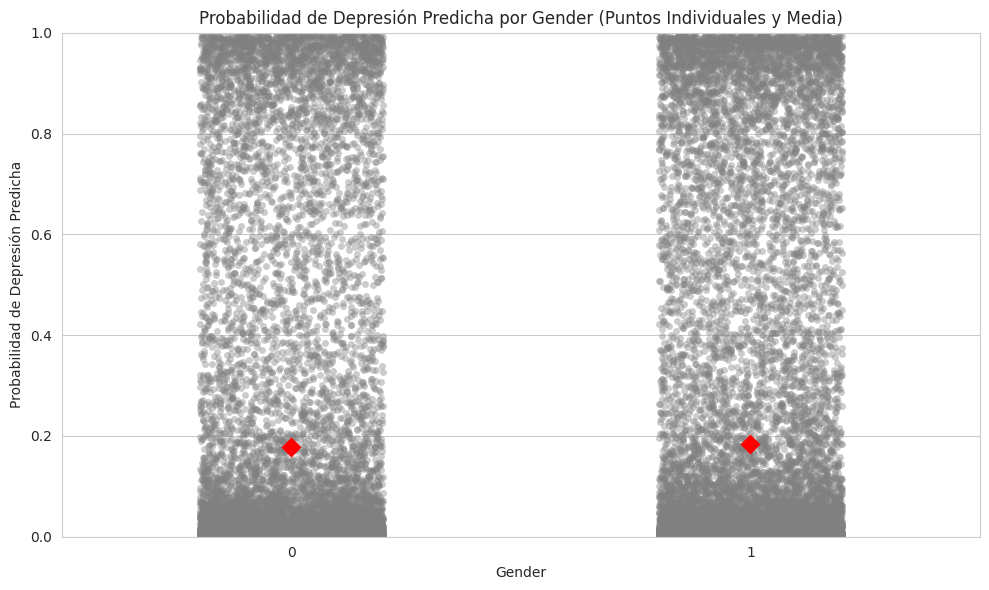

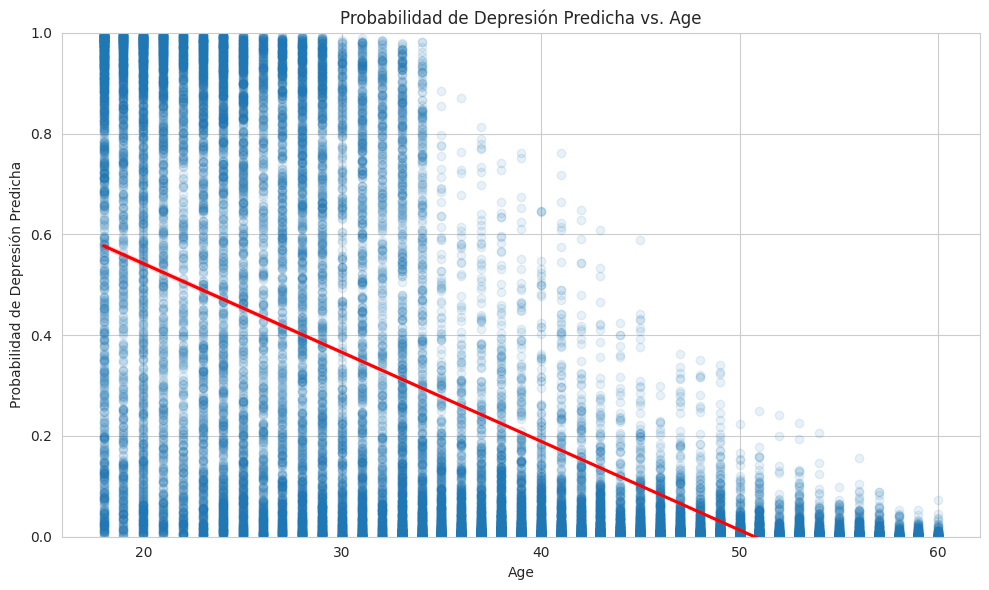

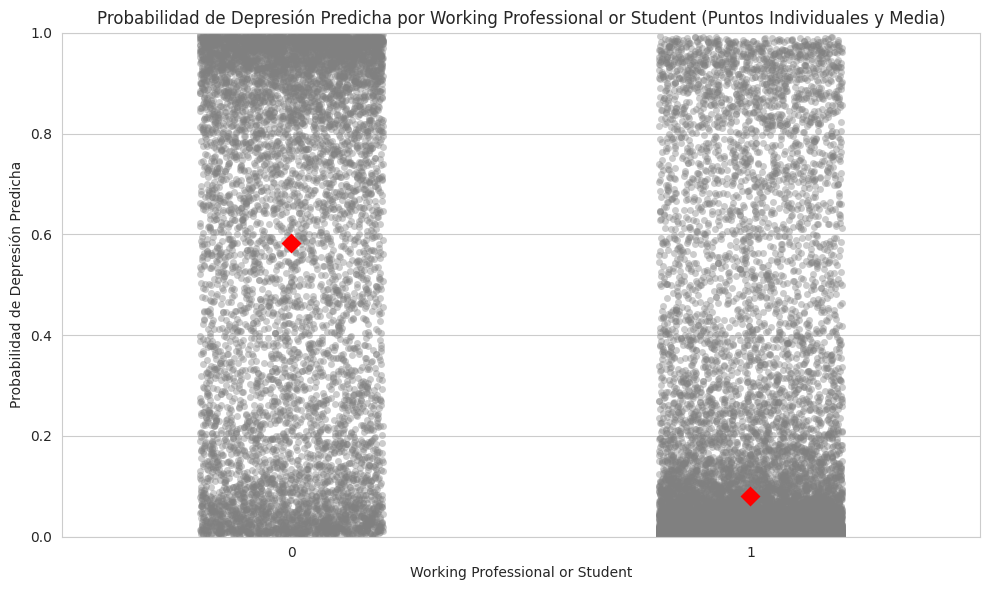

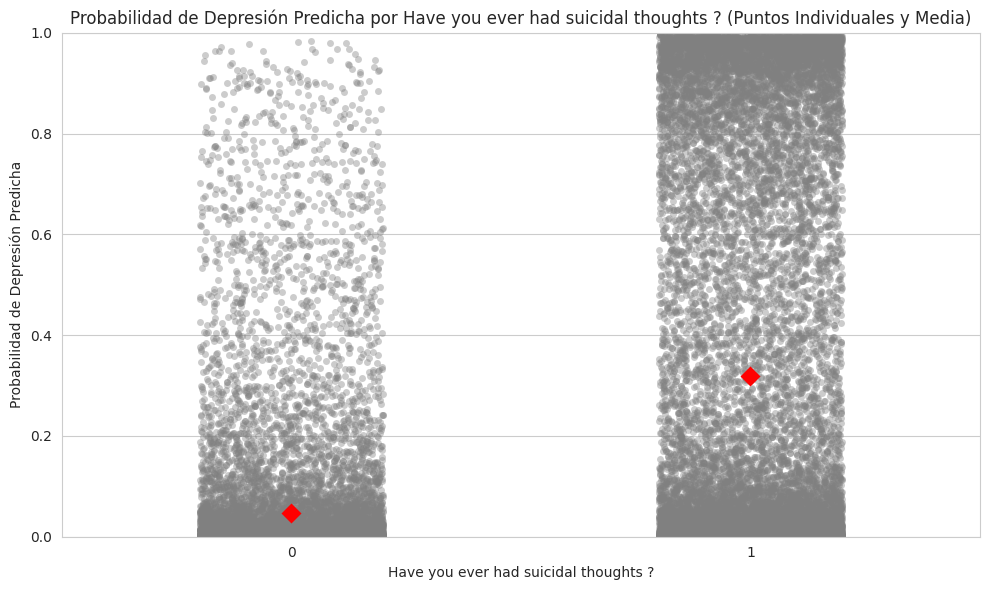

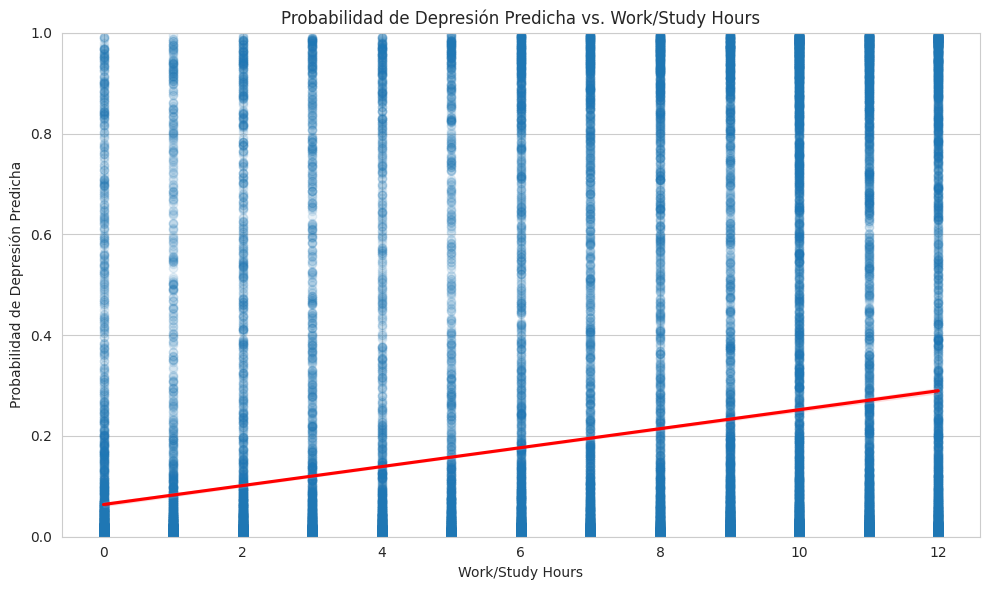

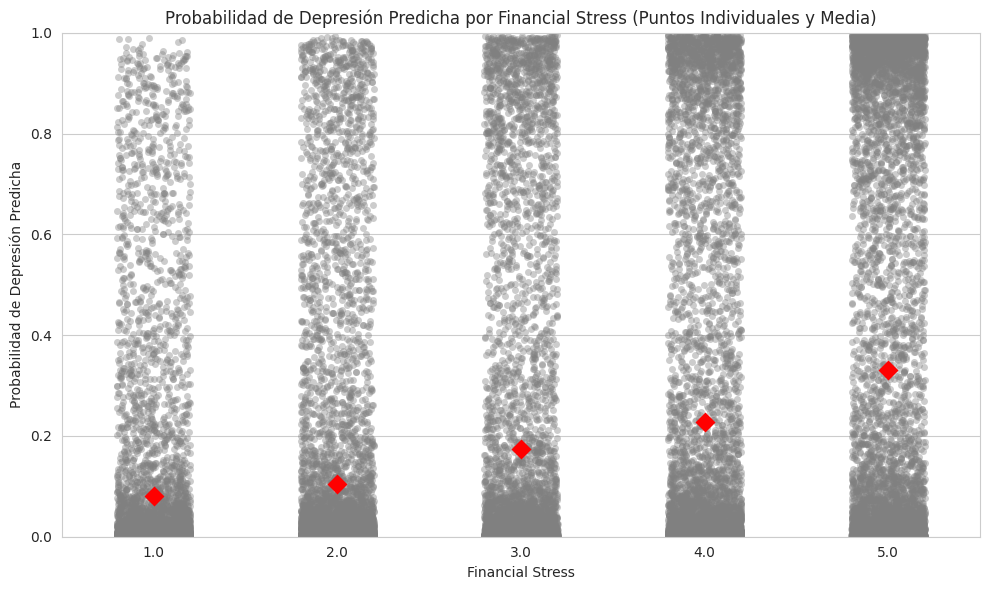

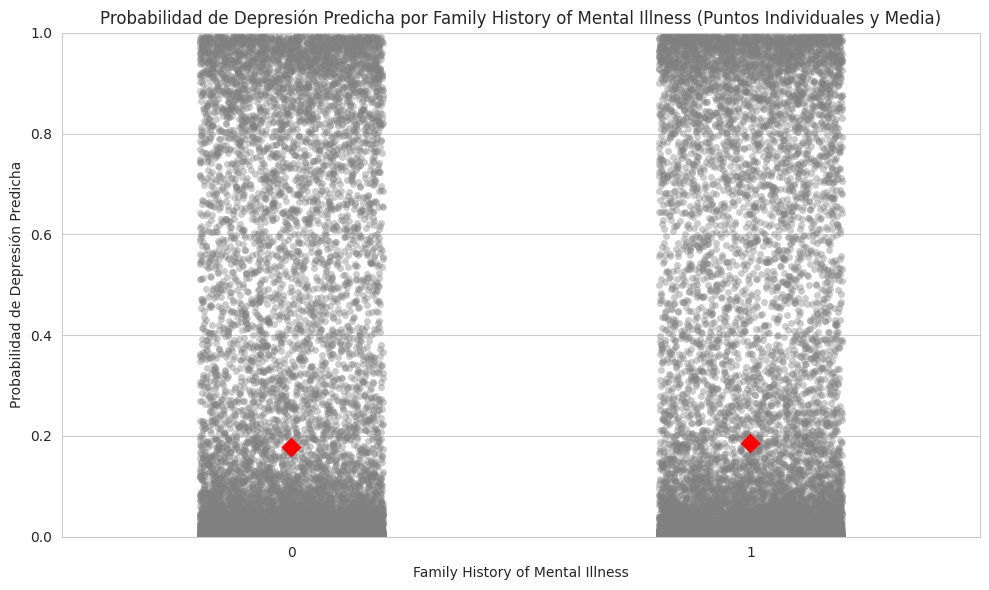

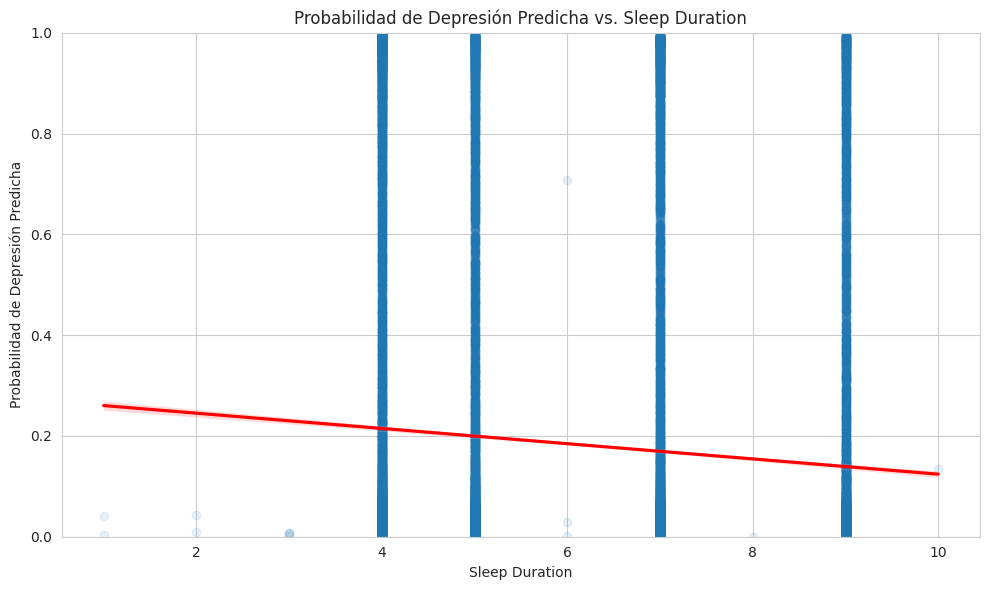

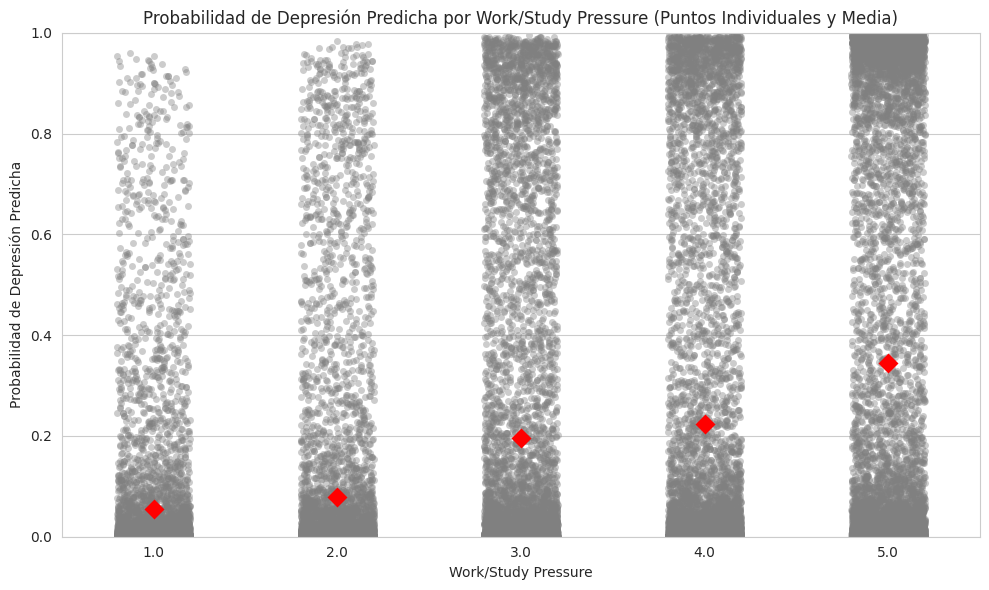

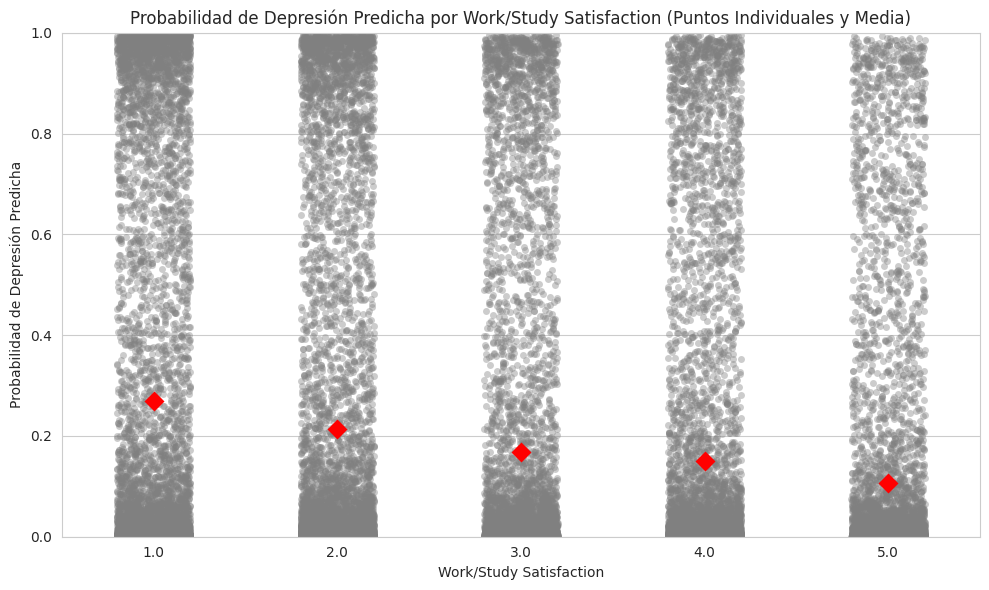

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# 2. Set the seaborn plotting style
sns.set_style('whitegrid')

# 3. Define a list named features_to_plot
features_to_plot = ['Gender', 'Age', 'Working Professional or Student', 'Have you ever had suicidal thoughts ?',
                    'Work/Study Hours', 'Financial Stress', 'Family History of Mental Illness',
                    'Sleep Duration', 'Work/Study Pressure', 'Work/Study Satisfaction']

# Features for which to show all individual points and the mean
features_with_individual_points_and_mean = [
    'Gender',
    'Working Professional or Student',
    'Have you ever had suicidal thoughts ?',
    'Financial Stress',
    'Family History of Mental Illness',
    'Work/Study Pressure',
    'Work/Study Satisfaction' # Added Work/Study Satisfaction here
]

# 4. Loop through each feature in the features_to_plot list
for feature in features_to_plot:
    # 5. Create a new figure for each plot
    plt.figure(figsize=(10, 6))

    # Determine the plotting strategy based on the feature
    if feature in features_with_individual_points_and_mean:
        # Plot all individual points using stripplot
        sns.stripplot(x=feature, y='Predicted_Depression_Probability', data=test_results_df,
                      jitter=0.2, alpha=0.4, color='grey', zorder=1)
        # Overlay with pointplot to show the mean (without error bars)
        sns.pointplot(x=feature, y='Predicted_Depression_Probability', data=test_results_df,
                      errorbar=None, color='red', marker='D', markersize=8, linestyles='', zorder=2)
        plt.title(f'Probabilidad de Depresión Predicha por {feature} (Puntos Individuales y Media)')
        plt.xlabel(feature)
        plt.ylabel('Probabilidad de Depresión Predicha')

    else: # Numerical features (Age, Work/Study Hours, Sleep Duration) - these are the only ones left now
        sns.regplot(x=feature, y='Predicted_Depression_Probability', data=test_results_df,
                    scatter_kws={'alpha':0.1}, line_kws={'color':'red'})
        plt.title(f'Probabilidad de Depresión Predicha vs. {feature}')
        plt.xlabel(feature)
        plt.ylabel('Probabilidad de Depresión Predicha')

    # 10. Adjust plot parameters for a tight layout
    plt.ylim(0, 1) # Ensure y-axis limits for probabilities
    plt.tight_layout()
    # 11. Display each plot
    plt.show()


In [ ]:
y_test_true = nueva_data_cleaned.iloc[100000:]['Depression']

print("Shape of y_test_true:", y_test_true.shape)
display(y_test_true.head())

Shape of y_test_true: (40645,)


,Depression
100043,1
100044,1
100045,0
100046,0
100047,0


## Convert Probabilities to Binary Predictions

### Subtask:
Convert the predicted depression probabilities (`probability_of_depression_test`) into binary predictions using a threshold of 0.5.

**Reasoning**:
To convert the predicted probabilities into binary predictions, I will apply a threshold of 0.5 to `probability_of_depression_test`. Values greater than or equal to 0.5 will be classified as 1 (depressed), and values below 0.5 will be classified as 0 (not depressed).



In [ ]:
y_pred_binary = (probability_of_depression_test >= 0.5).astype(int)

print("Shape of binary predictions:", y_pred_binary.shape)
print("First 10 binary predictions:", y_pred_binary[:10])
print("Count of 0s and 1s in binary predictions:\n", pd.Series(y_pred_binary).value_counts())

Shape of binary predictions: (40645,)
First 10 binary predictions: [1 1 0 0 0 1 0 0 0 0]
Count of 0s and 1s in binary predictions:
 0    33578
1     7067
Name: count, dtype: int64


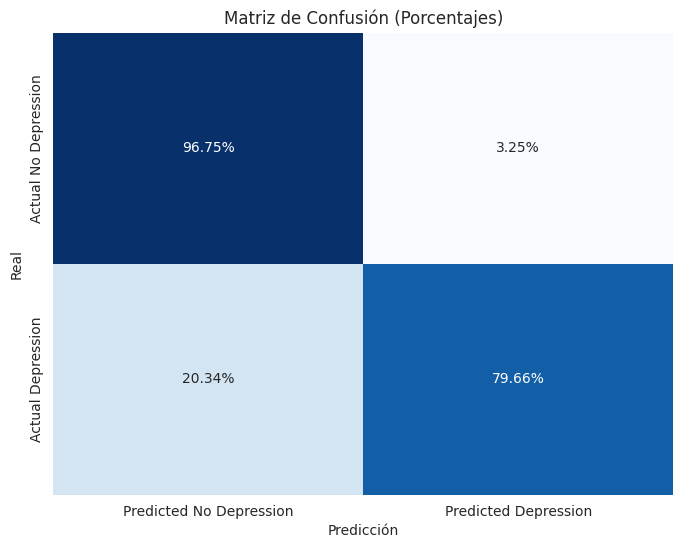

Interpretación de la Matriz de Confusión (Porcentajes):
  - Verdaderos Negativos (TN): 96.75% (del total de No Depresión real, el modelo predijo correctamente No Depresión)
  - Falsos Positivos (FP): 3.25% (del total de No Depresión real, el modelo predijo erróneamente Depresión)
  - Falsos Negativos (FN): 20.34% (del total de Depresión real, el modelo predijo erróneamente No Depresión)
  - Verdaderos Positivos (TP): 79.66% (del total de Depresión real, el modelo predijo correctamente Depresión)


In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Calculate the confusion matrix
cm = confusion_matrix(y_test_true, y_pred_binary)

# Calculate percentages from the confusion matrix
cm_percent = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

# Create a DataFrame for better labeling with percentages
cm_df_percent = pd.DataFrame(cm_percent,
                             index = ['Actual No Depression', 'Actual Depression'],
                             columns = ['Predicted No Depression', 'Predicted Depression'])

# Plot the confusion matrix as a heatmap with percentages
plt.figure(figsize=(8, 6))
sns.heatmap(cm_df_percent, annot=True, fmt='.2%', cmap='Blues', cbar=False,
            xticklabels=['Predicted No Depression', 'Predicted Depression'],
            yticklabels=['Actual No Depression', 'Actual Depression'])
plt.title('Matriz de Confusión (Porcentajes)')
plt.xlabel('Predicción')
plt.ylabel('Real')
plt.show()

print("Interpretación de la Matriz de Confusión (Porcentajes):")
print(f"  - Verdaderos Negativos (TN): {cm_percent[0, 0]:.2%} (del total de No Depresión real, el modelo predijo correctamente No Depresión)")
print(f"  - Falsos Positivos (FP): {cm_percent[0, 1]:.2%} (del total de No Depresión real, el modelo predijo erróneamente Depresión)")
print(f"  - Falsos Negativos (FN): {cm_percent[1, 0]:.2%} (del total de Depresión real, el modelo predijo erróneamente No Depresión)")
print(f"  - Verdaderos Positivos (TP): {cm_percent[1, 1]:.2%} (del total de Depresión real, el modelo predijo correctamente Depresión)")


In [ ]:
from sklearn.metrics import accuracy_score

# Calculate the accuracy score
accuracy = accuracy_score(y_test_true, y_pred_binary)

# Display the accuracy score
print(f"Accuracy Score: {accuracy:.4f}")

Accuracy Score: 0.9359


In [ ]:
y_pred_binary = (probability_of_depression_test >= 0.20).astype(int)

print("Shape of binary predictions:", y_pred_binary.shape)
print("First 10 binary predictions:", y_pred_binary[:10])
print("Count of 0s and 1s in binary predictions:\n", pd.Series(y_pred_binary).value_counts())

Shape of binary predictions: (40645,)
First 10 binary predictions: [1 1 1 0 0 1 0 0 0 0]
Count of 0s and 1s in binary predictions:
 0    30988
1     9657
Name: count, dtype: int64


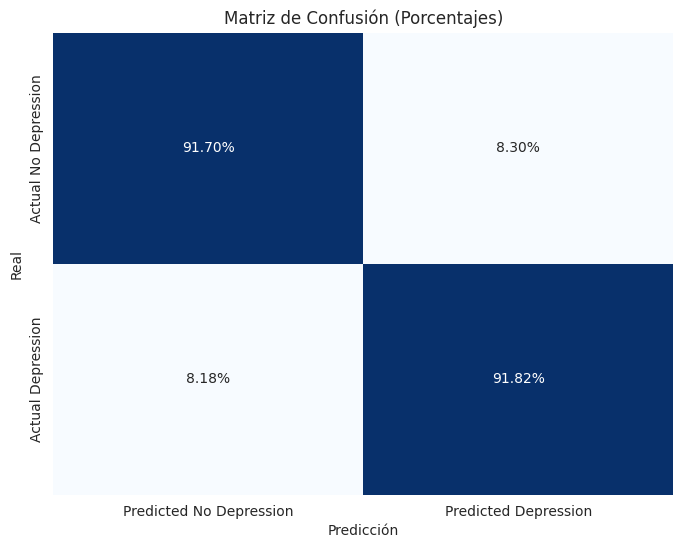

Interpretación de la Matriz de Confusión (Porcentajes):
  - Verdaderos Negativos (TN): 91.70% (del total de No Depresión real, el modelo predijo correctamente No Depresión)
  - Falsos Positivos (FP): 8.30% (del total de No Depresión real, el modelo predijo erróneamente Depresión)
  - Falsos Negativos (FN): 8.18% (del total de Depresión real, el modelo predijo erróneamente No Depresión)
  - Verdaderos Positivos (TP): 91.82% (del total de Depresión real, el modelo predijo correctamente Depresión)


In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Calculate the confusion matrix
cm = confusion_matrix(y_test_true, y_pred_binary)

# Calculate percentages from the confusion matrix
cm_percent = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

# Create a DataFrame for better labeling with percentages
cm_df_percent = pd.DataFrame(cm_percent,
                             index = ['Actual No Depression', 'Actual Depression'],
                             columns = ['Predicted No Depression', 'Predicted Depression'])

# Plot the confusion matrix as a heatmap with percentages
plt.figure(figsize=(8, 6))
sns.heatmap(cm_df_percent, annot=True, fmt='.2%', cmap='Blues', cbar=False,
            xticklabels=['Predicted No Depression', 'Predicted Depression'],
            yticklabels=['Actual No Depression', 'Actual Depression'])
plt.title('Matriz de Confusión (Porcentajes)')
plt.xlabel('Predicción')
plt.ylabel('Real')
plt.show()

print("Interpretación de la Matriz de Confusión (Porcentajes):")
print(f"  - Verdaderos Negativos (TN): {cm_percent[0, 0]:.2%} (del total de No Depresión real, el modelo predijo correctamente No Depresión)")
print(f"  - Falsos Positivos (FP): {cm_percent[0, 1]:.2%} (del total de No Depresión real, el modelo predijo erróneamente Depresión)")
print(f"  - Falsos Negativos (FN): {cm_percent[1, 0]:.2%} (del total de Depresión real, el modelo predijo erróneamente No Depresión)")
print(f"  - Verdaderos Positivos (TP): {cm_percent[1, 1]:.2%} (del total de Depresión real, el modelo predijo correctamente Depresión)")

In [ ]:
from sklearn.metrics import accuracy_score

# Calculate the accuracy score
accuracy = accuracy_score(y_test_true, y_pred_binary)

# Display the accuracy score
print(f"Accuracy Score: {accuracy:.4f}")

Accuracy Score: 0.9172
